Mounted at /content/drive
SETSTOP-KGQA COST-MATCHED BUDGET ABLATION
Runtime: T4 GPU required
Python: 3.13.15
Transformers: 5.17.0
PyTorch: 2.11.0+cu130
Action caps: [2, 4, 6, 8, 10, 12]
Frozen controller threshold: 0.7100000000000001
Frozen answer threshold: 0.6699999999999999
Output directory: /content/drive/MyDrive/SetStop_KGQA/outputs/cost_matched_ablation_v1
GPU: Tesla T4


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[transformers] Qwen2ForSequenceClassification LOAD REPORT from: Qwen/Qwen2.5-0.5B-Instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Models loaded successfully.
Usable questions: dev=118, test=736
dev: 25/118 questions | this run 0.7 min
dev: 50/118 questions | this run 1.5 min
dev: 75/118 questions | this run 2.2 min
dev: 100/118 questions | this run 3.0 min
dev: 118/118 questions | this run 3.6 min
test: 25/736 questions | this run 0.8 min
test: 50/736 questions | this run 1.6 min
test: 75/736 questions | this run 2.3 min
test: 100/736 questions | this run 3.1 min
test: 125/736 questions | this run 3.9 min
test: 150/736 questions | this run 4.7 min
test: 175/736 questions | this run 5.5 min
test: 200/736 questions | this run 6.3 min
test: 225/736 questions | this run 7.1 min
test: 250/736 questions | this run 7.8 min
test: 275/736 questions | this run 8.6 min
test: 300/736 questions | this run 9.4 min
test: 325/736 questions | this run 10.1 min
test: 350/736 questions | this run 10.9 min
test: 375/736 questions | this run 11.7 min
test: 400/736 questions | this run 12.5 min
test: 425/736 questions | this run 13.2 

ImportError: cannot import name 'FontPath' from 'matplotlib.font_manager' (/usr/local/lib/python3.13/dist-packages/matplotlib/font_manager.py)

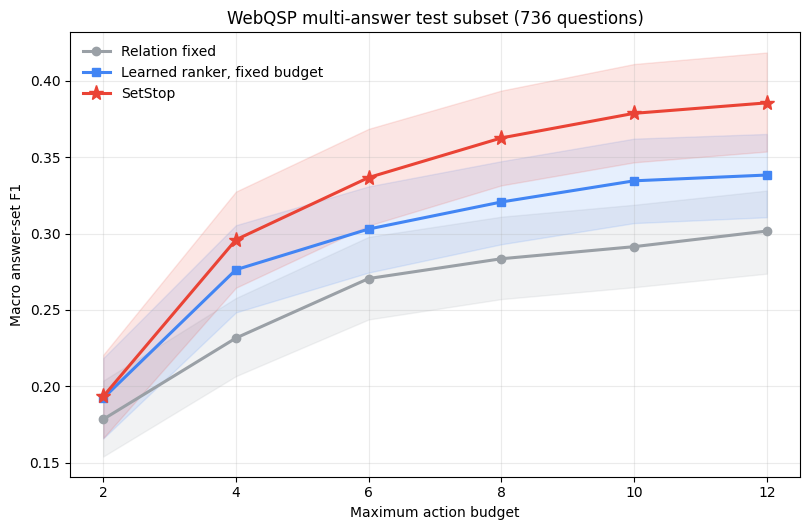

In [2]:
import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "transformers==5.17.0",
        "peft",
        "accelerate",
        "bitsandbytes",
        "safetensors",
        "pandas>=2.0",
        "matplotlib>=3.7",
    ],
    check=True,
)

import collections
import gc
import hashlib
import json
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from google.colab import drive
from peft import PeftModel
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
)


# =============================================================================
# 1. REPRODUCIBILITY, DRIVE, AND CONFIGURATION
# =============================================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

for variable_name in ["controller", "controller_base", "answer_model"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/SetStop_KGQA")
DATA_DIR = ROOT / "data/extracted/webqsp"

CONTROLLER_MODEL_PATH = (
    ROOT / "models/setstop_qwen_gain_controller_v1"
)

ANSWER_MODEL_PATH = (
    ROOT / "models/answer_node_minilm_v1"
)

CONTROLLER_THRESHOLD_PATH = (
    ROOT
    / "outputs/controller_training_v1/"
      "dev_stop_threshold_v1.json"
)

ANSWER_THRESHOLD_PATH = (
    ROOT
    / "outputs/answer_recognizer_v1/"
      "answer_recognizer_threshold_v1.json"
)

PREVIOUS_E2E_SUMMARY_PATH = (
    ROOT
    / "outputs/end_to_end_test_v1/"
      "end_to_end_summary_v1.json"
)

OUTPUT_ROOT = (
    ROOT / "outputs/cost_matched_ablation_v1"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

CONTROLLER_BASE_MODEL = (
    "Qwen/Qwen2.5-0.5B-Instruct"
)

MAX_HOPS = 3
MAX_ANSWERS = 50
MAX_FRONTIER_CANDIDATES = 16

ACTION_CAPS = [2, 4, 6, 8, 10, 12]
MAX_ACTIONS = max(ACTION_CAPS)

# SetStop used 5.952 actions on average in Notebook 06.
# Six is therefore the predeclared rounded action-matched fixed budget.
REFERENCE_MATCHED_CAP = 6

CONTROLLER_BATCH_SIZE = 64
ANSWER_BATCH_SIZE = 128
BOOTSTRAP_SAMPLES = 5000

GAIN_VALUES = np.asarray(
    [0.0, 1.0, 2.0, 3.5],
    dtype=np.float64,
)

POLICIES = [
    "relation_fixed",
    "learned_ranker_fixed",
    "setstop",
]

POLICY_LABELS = {
    "relation_fixed": "Relation fixed",
    "learned_ranker_fixed":
        "Learned ranker, fixed budget",
    "setstop": "SetStop",
}

required_paths = [
    DATA_DIR / "dev_simple.json",
    DATA_DIR / "test_simple.json",
    DATA_DIR / "entities.txt",
    DATA_DIR / "relations.txt",
    CONTROLLER_MODEL_PATH,
    ANSWER_MODEL_PATH,
    CONTROLLER_THRESHOLD_PATH,
    ANSWER_THRESHOLD_PATH,
    PREVIOUS_E2E_SUMMARY_PATH,
]

for path in required_paths:
    assert path.exists(), (
        f"Missing required input:\n{path}"
    )

controller_threshold_data = json.loads(
    CONTROLLER_THRESHOLD_PATH.read_text(
        encoding="utf-8"
    )
)

answer_threshold_data = json.loads(
    ANSWER_THRESHOLD_PATH.read_text(
        encoding="utf-8"
    )
)

CONTROLLER_THRESHOLD = float(
    controller_threshold_data[
        "selected_threshold"
    ]
)

ANSWER_THRESHOLD = float(
    answer_threshold_data[
        "selected_threshold"
    ]
)

assert abs(
    CONTROLLER_THRESHOLD - 0.71
) < 1e-6

assert abs(
    ANSWER_THRESHOLD - 0.67
) < 1e-6

assert REFERENCE_MATCHED_CAP in ACTION_CAPS

print("=" * 108)
print(
    "SETSTOP-KGQA COST-MATCHED "
    "BUDGET ABLATION"
)
print("=" * 108)
print("Runtime: T4 GPU required")
print("Python:", sys.version.split()[0])
print(
    "Transformers:",
    transformers.__version__,
)
print("PyTorch:", torch.__version__)
print("Action caps:", ACTION_CAPS)
print(
    "Frozen controller threshold:",
    CONTROLLER_THRESHOLD,
)
print(
    "Frozen answer threshold:",
    ANSWER_THRESHOLD,
)
print("Output directory:", OUTPUT_ROOT)

assert torch.cuda.is_available(), (
    "Select Runtime > Change runtime type > T4 GPU."
)

GPU_NAME = torch.cuda.get_device_name(0)

print("GPU:", GPU_NAME)
print("=" * 108)


# =============================================================================
# 2. DATA AND GRAPH HELPERS
# Exact Notebook 06 semantics
# =============================================================================

def read_vocabulary(path):
    with open(
        path,
        encoding="utf-8",
    ) as file:
        return [
            line.rstrip("\n")
            for line in file
        ]


ENTITY_NAMES = read_vocabulary(
    DATA_DIR / "entities.txt"
)

RELATION_NAMES = read_vocabulary(
    DATA_DIR / "relations.txt"
)

ENTITY_TO_ID = {
    name: index
    for index, name
    in enumerate(ENTITY_NAMES)
}

RELATION_TO_ID = {
    name: index
    for index, name
    in enumerate(RELATION_NAMES)
}


def iter_jsonl(path):
    with open(
        path,
        encoding="utf-8",
    ) as file:
        for line_number, line in enumerate(
            file,
            start=1,
        ):
            if not line.strip():
                continue

            try:
                yield json.loads(line)

            except Exception as error:
                raise ValueError(
                    f"Invalid JSON at "
                    f"{path}:{line_number}"
                ) from error


def entity_index(value):
    if isinstance(
        value,
        (int, np.integer),
    ):
        return int(value)

    if isinstance(value, str):
        return ENTITY_TO_ID.get(value)

    if isinstance(value, dict):
        for key in [
            "kb_id",
            "id",
            "entity",
        ]:
            if key in value:
                return entity_index(
                    value[key]
                )

    return None


def relation_index(value):
    if isinstance(
        value,
        (int, np.integer),
    ):
        return int(value)

    if isinstance(value, str):
        return RELATION_TO_ID.get(value)

    return None


def get_question(example):
    for key in [
        "question",
        "text",
        "query",
    ]:
        value = example.get(key)

        if isinstance(value, str):
            return value.strip()

    raise KeyError(
        "Question field missing"
    )


def get_topic_ids(example):
    raw = example.get(
        "entities",
        example.get(
            "topic_entities",
            [],
        ),
    )

    values = {
        entity_index(item)
        for item in raw
    }

    return {
        item
        for item in values
        if item is not None
    }


def get_gold_ids(example):
    values = {
        entity_index(item)
        for item in example.get(
            "answers",
            [],
        )
    }

    return {
        item
        for item in values
        if item is not None
    }


def get_graph(example):
    subgraph = example.get(
        "subgraph",
        {},
    )

    nodes = {
        entity_index(item)
        for item in subgraph.get(
            "entities",
            [],
        )
    }

    nodes.discard(None)

    raw_edges = subgraph.get(
        "tuples",
        subgraph.get(
            "triples",
            [],
        ),
    )

    edges = []

    for row in raw_edges:
        if isinstance(row, dict):
            subject = entity_index(
                row.get(
                    "subject",
                    row.get("s"),
                )
            )

            relation = relation_index(
                row.get(
                    "relation",
                    row.get("r"),
                )
            )

            object_entity = entity_index(
                row.get(
                    "object",
                    row.get("o"),
                )
            )

        else:
            if len(row) != 3:
                continue

            subject = entity_index(
                row[0]
            )

            relation = relation_index(
                row[1]
            )

            object_entity = entity_index(
                row[2]
            )

        if (
            subject is None
            or relation is None
            or object_entity is None
        ):
            continue

        subject = int(subject)
        relation = int(relation)
        object_entity = int(
            object_entity
        )

        edges.append(
            (
                subject,
                relation,
                object_entity,
            )
        )

        nodes.add(subject)
        nodes.add(object_entity)

    return nodes, edges


def get_question_id(
    split,
    example,
    line_number,
):
    for key in [
        "id",
        "qid",
        "question_id",
    ]:
        if key in example:
            return str(example[key])

    digest = hashlib.sha1(
        get_question(example).encode(
            "utf-8"
        )
    ).hexdigest()[:12]

    return (
        f"{split}_{line_number}_"
        f"{digest}"
    )


def relation_name(relation_id):
    if (
        0 <= relation_id
        < len(RELATION_NAMES)
    ):
        return RELATION_NAMES[
            relation_id
        ]

    return f"relation_{relation_id}"


def stable_seed(text):
    digest = hashlib.sha1(
        text.encode("utf-8")
    ).hexdigest()[:8]

    return (
        SEED
        + int(digest, 16)
    )


def build_grouped_adjacency(edges):
    temporary = (
        collections.defaultdict(
            lambda:
            collections.defaultdict(
                set
            )
        )
    )

    for (
        subject,
        relation,
        object_entity,
    ) in edges:
        temporary[
            subject
        ][
            relation
        ].add(
            object_entity
        )

    return {
        source: {
            relation: sorted(targets)
            for relation, targets
            in relation_map.items()
        }
        for source, relation_map
        in temporary.items()
    }


def get_frontier(
    visited,
    node_depth,
    expanded,
    adjacency,
):
    branches = []

    for source in sorted(visited):
        source_depth = node_depth.get(
            source,
            MAX_HOPS + 1,
        )

        if source_depth >= MAX_HOPS:
            continue

        for (
            relation,
            targets,
        ) in adjacency.get(
            source,
            {},
        ).items():
            if (
                source,
                relation,
            ) in expanded:
                continue

            branches.append({
                "source": source,
                "relation": relation,
                "targets": targets,
                "source_depth":
                    source_depth,
                "target_depth":
                    source_depth + 1,
                "target_count":
                    len(targets),
            })

    return branches


def tokenize_relation(text):
    return set(
        re.findall(
            r"[a-z0-9]+",
            text.lower().replace(
                "_",
                " ",
            ),
        )
    )


def relation_overlap(
    question,
    relation_id,
):
    return len(
        tokenize_relation(question)
        & tokenize_relation(
            relation_name(
                relation_id
            )
        )
    )


def retrieve_frontier(
    branches,
    question,
):
    ranked = sorted(
        branches,
        key=lambda branch: (
            -relation_overlap(
                question,
                branch["relation"],
            ),
            branch["source_depth"],
            -branch["target_count"],
            branch["relation"],
            branch["source"],
        ),
    )

    return ranked[
        :MAX_FRONTIER_CANDIDATES
    ]


def expand_branch(
    branch,
    visited,
    node_depth,
    node_paths,
    expanded,
):
    source = branch["source"]
    relation = branch["relation"]

    expanded.add(
        (
            source,
            relation,
        )
    )

    source_path = node_paths.get(
        source,
        [],
    )

    target_path = (
        source_path
        + [relation]
    )

    for target in branch["targets"]:
        visited.add(target)

        old_depth = node_depth.get(
            target
        )

        if (
            old_depth is None
            or branch["target_depth"]
            < old_depth
        ):
            node_depth[target] = (
                branch["target_depth"]
            )

            node_paths[target] = list(
                target_path
            )


def reachable_gold_from_branch(
    branch,
    adjacency,
    expanded,
    unseen_gold,
):
    queue = collections.deque()
    best_depth = {}

    for target in branch["targets"]:
        best_depth[target] = (
            branch["target_depth"]
        )

        queue.append(
            (
                target,
                branch["target_depth"],
            )
        )

    reachable = set()

    while queue:
        node, depth = queue.popleft()

        if node in unseen_gold:
            reachable.add(node)

        if depth >= MAX_HOPS:
            continue

        for (
            relation,
            targets,
        ) in adjacency.get(
            node,
            {},
        ).items():
            if (
                node,
                relation,
            ) in expanded:
                continue

            next_depth = depth + 1

            for target in targets:
                previous_depth = (
                    best_depth.get(
                        target
                    )
                )

                if (
                    previous_depth
                    is None
                    or next_depth
                    < previous_depth
                ):
                    best_depth[target] = (
                        next_depth
                    )

                    queue.append(
                        (
                            target,
                            next_depth,
                        )
                    )

    return reachable


def remaining_gold_is_reachable(
    branches,
    adjacency,
    expanded,
    gold,
    truly_visited_answers,
):
    unseen_gold = (
        gold
        - truly_visited_answers
    )

    if not unseen_gold:
        return False

    for branch in branches:
        if reachable_gold_from_branch(
            branch,
            adjacency,
            expanded,
            unseen_gold,
        ):
            return True

    return False


# =============================================================================
# 3. LOAD FROZEN MODELS
# =============================================================================

controller_tokenizer = (
    AutoTokenizer.from_pretrained(
        CONTROLLER_MODEL_PATH,
        use_fast=True,
    )
)

if controller_tokenizer.pad_token is None:
    controller_tokenizer.pad_token = (
        controller_tokenizer.eos_token
    )

controller_quantization = (
    BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=
            torch.float16,
    )
)

controller_base = (
    AutoModelForSequenceClassification
    .from_pretrained(
        CONTROLLER_BASE_MODEL,
        num_labels=4,
        id2label={
            0: "0",
            1: "1",
            2: "2",
            3: "3_plus",
        },
        label2id={
            "0": 0,
            "1": 1,
            "2": 2,
            "3_plus": 3,
        },
        quantization_config=
            controller_quantization,
        device_map={"": 0},
        dtype=torch.float16,
    )
)

controller_base.config.pad_token_id = (
    controller_tokenizer.pad_token_id
)

controller = PeftModel.from_pretrained(
    controller_base,
    CONTROLLER_MODEL_PATH,
    is_trainable=False,
)

controller.eval()

answer_tokenizer = (
    AutoTokenizer.from_pretrained(
        ANSWER_MODEL_PATH,
        use_fast=True,
    )
)

answer_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        ANSWER_MODEL_PATH,
        dtype=torch.float16,
    )
)

answer_model = answer_model.to(
    "cuda"
)

answer_model.eval()

print("Models loaded successfully.")


@torch.inference_mode()
def controller_probabilities(texts):
    outputs = []

    for start in range(
        0,
        len(texts),
        CONTROLLER_BATCH_SIZE,
    ):
        batch = texts[
            start:
            start + CONTROLLER_BATCH_SIZE
        ]

        encoded = controller_tokenizer(
            batch,
            truncation=True,
            max_length=256,
            padding=True,
            return_tensors="pt",
        )

        encoded = {
            key: value.to(
                controller.device
            )
            for key, value
            in encoded.items()
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = controller(
                **encoded
            ).logits

        outputs.append(
            torch.softmax(
                logits.float(),
                dim=-1,
            ).cpu().numpy()
        )

    return np.concatenate(
        outputs,
        axis=0,
    )


@torch.inference_mode()
def answer_probabilities(texts):
    outputs = []

    for start in range(
        0,
        len(texts),
        ANSWER_BATCH_SIZE,
    ):
        batch = texts[
            start:
            start + ANSWER_BATCH_SIZE
        ]

        encoded = answer_tokenizer(
            batch,
            truncation=True,
            max_length=192,
            padding=True,
            return_tensors="pt",
        )

        encoded = {
            key: value.to("cuda")
            for key, value
            in encoded.items()
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = answer_model(
                **encoded
            ).logits

        outputs.append(
            torch.softmax(
                logits.float(),
                dim=-1,
            )[:, 1].cpu().numpy()
        )

    return np.concatenate(
        outputs,
        axis=0,
    )


# =============================================================================
# 4. EXACT NOTEBOOK-06 MODEL INPUTS
# =============================================================================

def make_controller_text(
    question,
    predicted_answer_count,
    visited_count,
    step,
    branch,
    history,
):
    history_text = (
        " -> ".join(history[-6:])
        if history
        else "none"
    )

    return (
        f"Question: {question}\n"
        f"Answers found so far: "
        f"{predicted_answer_count}\n"
        f"Visited entities: "
        f"{visited_count}\n"
        f"Search step: {step}\n"
        f"Source depth: "
        f"{branch['source_depth']}\n"
        f"Candidate relation: "
        f"{relation_name(branch['relation'])}\n"
        f"Candidate target count: "
        f"{branch['target_count']}\n"
        f"Recent relations: {history_text}"
    )


def make_answer_text(
    question,
    branch,
    source_path,
    target,
    adjacency,
):
    relation_path = (
        source_path
        + [branch["relation"]]
    )

    path_text = " -> ".join(
        relation_name(relation)
        for relation in relation_path
    )

    return (
        f"Question: {question}\n"
        f"Candidate relation path: "
        f"{path_text}\n"
        f"Candidate depth: "
        f"{branch['target_depth']}\n"
        f"Incoming relation: "
        f"{relation_name(branch['relation'])}\n"
        f"Entities returned by final relation: "
        f"{branch['target_count']}\n"
        f"Candidate outgoing relation count: "
        f"{len(adjacency.get(target, {}))}"
    )


def recognize_branch_answers(
    question,
    branch,
    node_paths,
    adjacency,
    node_answer_scores,
    predicted_answers,
):
    source_path = node_paths.get(
        branch["source"],
        [],
    )

    texts = [
        make_answer_text(
            question=question,
            branch=branch,
            source_path=source_path,
            target=target,
            adjacency=adjacency,
        )
        for target in branch["targets"]
    ]

    probabilities = (
        answer_probabilities(texts)
    )

    newly_predicted = set()

    for target, probability in zip(
        branch["targets"],
        probabilities,
    ):
        previous_score = (
            node_answer_scores.get(
                target,
                0.0,
            )
        )

        best_score = max(
            previous_score,
            float(probability),
        )

        node_answer_scores[target] = (
            best_score
        )

        if best_score >= ANSWER_THRESHOLD:
            if target not in predicted_answers:
                newly_predicted.add(
                    target
                )

            predicted_answers.add(
                target
            )

    return newly_predicted


# =============================================================================
# 5. RESULTS AND SNAPSHOTS
# =============================================================================

def create_result(
    split,
    qid,
    policy,
    budget_cap,
    gold_answers,
    predicted_answers,
    truly_visited_answers,
    actions,
    retrieved_edges,
    over_search_actions,
    stop_reason,
    premature_stop,
    frontier_truncations,
):
    true_positives = len(
        predicted_answers
        & gold_answers
    )

    false_positives = len(
        predicted_answers
        - gold_answers
    )

    false_negatives = len(
        gold_answers
        - predicted_answers
    )

    precision = (
        true_positives
        / len(predicted_answers)
        if predicted_answers
        else 0.0
    )

    recall = (
        true_positives
        / len(gold_answers)
    )

    answer_f1 = (
        2
        * precision
        * recall
        / (precision + recall)
        if precision + recall
        else 0.0
    )

    return {
        "split": split,
        "qid": qid,
        "policy": policy,
        "method":
            POLICY_LABELS[policy],
        "budget_cap":
            int(budget_cap),
        "gold_answer_count":
            len(gold_answers),
        "predicted_answer_count":
            len(predicted_answers),
        "truly_visited_answer_count":
            len(truly_visited_answers),
        "true_positive_count":
            true_positives,
        "false_positive_count":
            false_positives,
        "false_negative_count":
            false_negatives,
        "precision":
            float(precision),
        "recall":
            float(recall),
        "answer_f1":
            float(answer_f1),
        "exact_match":
            int(
                predicted_answers
                == gold_answers
            ),
        "complete_recall":
            int(recall == 1.0),
        "incomplete_set":
            int(recall < 1.0),
        "actions":
            int(actions),
        "retrieved_edges":
            int(retrieved_edges),
        "over_search_actions":
            int(over_search_actions),
        "premature_stop":
            int(premature_stop),
        "frontier_truncations":
            int(frontier_truncations),
        "stop_reason":
            stop_reason,
    }


def capture_state(
    actions,
    retrieved_edges,
    predicted_answers,
    truly_visited_answers,
    over_search_actions,
    frontier_truncations,
):
    return {
        "actions":
            int(actions),
        "retrieved_edges":
            int(retrieved_edges),
        "predicted_answers":
            set(predicted_answers),
        "truly_visited_answers":
            set(truly_visited_answers),
        "over_search_actions":
            int(over_search_actions),
        "frontier_truncations":
            int(frontier_truncations),
    }


def result_from_state(
    split,
    qid,
    policy,
    budget_cap,
    gold,
    state,
    stop_reason,
    premature_stop=False,
):
    return create_result(
        split=split,
        qid=qid,
        policy=policy,
        budget_cap=budget_cap,
        gold_answers=gold,
        predicted_answers=
            state["predicted_answers"],
        truly_visited_answers=
            state[
                "truly_visited_answers"
            ],
        actions=
            state["actions"],
        retrieved_edges=
            state["retrieved_edges"],
        over_search_actions=
            state[
                "over_search_actions"
            ],
        stop_reason=stop_reason,
        premature_stop=
            premature_stop,
        frontier_truncations=
            state[
                "frontier_truncations"
            ],
    )


# =============================================================================
# 6. LEARNED RANKER AND SETSTOP BUDGET GRID
# One maximum-budget rollout gives exact prefixes for all caps.
# =============================================================================

def run_learned_budget_grid(
    split,
    qid,
    example,
):
    question = get_question(example)
    gold = get_gold_ids(example)
    topics = get_topic_ids(example)

    _, edges = get_graph(example)

    adjacency = build_grouped_adjacency(
        edges
    )

    visited = set(topics)

    node_depth = {
        topic: 0
        for topic in topics
    }

    node_paths = {
        topic: []
        for topic in topics
    }

    expanded = set()
    history = []

    node_answer_scores = {}
    predicted_answers = set()

    truly_visited_answers = (
        visited & gold
    )

    actions = 0
    retrieved_edges = 0
    over_search_actions = 0
    frontier_truncations = 0

    states_by_action = {
        0: capture_state(
            actions,
            retrieved_edges,
            predicted_answers,
            truly_visited_answers,
            over_search_actions,
            frontier_truncations,
        )
    }

    decision_snapshots = []
    terminal_reason = None

    while actions < MAX_ACTIONS:
        all_branches = get_frontier(
            visited,
            node_depth,
            expanded,
            adjacency,
        )

        if not all_branches:
            terminal_reason = (
                "empty_frontier"
            )
            break

        if (
            len(all_branches)
            > MAX_FRONTIER_CANDIDATES
        ):
            frontier_truncations += 1

        branches = retrieve_frontier(
            all_branches,
            question,
        )

        controller_texts = [
            make_controller_text(
                question=question,
                predicted_answer_count=
                    len(predicted_answers),
                visited_count=
                    len(visited),
                step=actions,
                branch=branch,
                history=history,
            )
            for branch in branches
        ]

        probabilities = (
            controller_probabilities(
                controller_texts
            )
        )

        positive_gain = (
            1.0
            - probabilities[:, 0]
        )

        expected_gain = (
            probabilities
            @ GAIN_VALUES
        )

        maximum_positive_gain = float(
            np.max(positive_gain)
        )

        should_stop = (
            maximum_positive_gain
            < CONTROLLER_THRESHOLD
        )

        premature_if_stopped = False

        if should_stop:
            premature_if_stopped = (
                remaining_gold_is_reachable(
                    branches=all_branches,
                    adjacency=adjacency,
                    expanded=expanded,
                    gold=gold,
                    truly_visited_answers=
                        truly_visited_answers,
                )
            )

        # SetStop checks stopping before expansion.
        pre_action_state = capture_state(
            actions,
            retrieved_edges,
            predicted_answers,
            truly_visited_answers,
            over_search_actions,
            frontier_truncations,
        )

        pre_action_state.update({
            "maximum_positive_gain":
                maximum_positive_gain,
            "should_stop":
                bool(should_stop),
            "premature_if_stopped":
                bool(
                    premature_if_stopped
                ),
        })

        decision_snapshots.append(
            pre_action_state
        )

        best_index = int(
            np.argmax(expected_gain)
        )

        chosen = branches[best_index]

        true_complete_before = (
            truly_visited_answers
            == gold
        )

        expand_branch(
            chosen,
            visited,
            node_depth,
            node_paths,
            expanded,
        )

        recognize_branch_answers(
            question=question,
            branch=chosen,
            node_paths=node_paths,
            adjacency=adjacency,
            node_answer_scores=
                node_answer_scores,
            predicted_answers=
                predicted_answers,
        )

        actions += 1

        retrieved_edges += (
            chosen["target_count"]
        )

        history.append(
            relation_name(
                chosen["relation"]
            )
        )

        truly_visited_answers = (
            visited & gold
        )

        if true_complete_before:
            over_search_actions += 1

        states_by_action[actions] = (
            capture_state(
                actions,
                retrieved_edges,
                predicted_answers,
                truly_visited_answers,
                over_search_actions,
                frontier_truncations,
            )
        )

    if terminal_reason is None:
        terminal_reason = (
            "action_budget"
            if actions >= MAX_ACTIONS
            else "empty_frontier"
        )

    terminal_actions = actions

    terminal_state = (
        states_by_action[
            terminal_actions
        ]
    )

    results = []

    for cap in ACTION_CAPS:
        if terminal_actions >= cap:
            fixed_state = (
                states_by_action[cap]
            )

            fixed_reason = (
                "action_budget"
            )

        else:
            fixed_state = (
                terminal_state
            )

            fixed_reason = (
                terminal_reason
            )

        results.append(
            result_from_state(
                split=split,
                qid=qid,
                policy=
                    "learned_ranker_fixed",
                budget_cap=cap,
                gold=gold,
                state=fixed_state,
                stop_reason=fixed_reason,
                premature_stop=False,
            )
        )

        # A stopping decision at action == cap
        # would not be evaluated by a run whose
        # while-condition is actions < cap.
        stopping_snapshot = next(
            (
                snapshot
                for snapshot
                in decision_snapshots
                if (
                    snapshot["actions"]
                    < cap
                    and snapshot[
                        "should_stop"
                    ]
                )
            ),
            None,
        )

        if stopping_snapshot is not None:
            setstop_state = (
                stopping_snapshot
            )

            setstop_reason = (
                "learned_stop"
            )

            setstop_premature = (
                stopping_snapshot[
                    "premature_if_stopped"
                ]
            )

        else:
            setstop_state = (
                fixed_state
            )

            setstop_reason = (
                fixed_reason
            )

            setstop_premature = False

        results.append(
            result_from_state(
                split=split,
                qid=qid,
                policy="setstop",
                budget_cap=cap,
                gold=gold,
                state=setstop_state,
                stop_reason=
                    setstop_reason,
                premature_stop=
                    setstop_premature,
            )
        )

    return results


# =============================================================================
# 7. RELATION-HEURISTIC BUDGET GRID
# =============================================================================

def run_relation_budget_grid(
    split,
    qid,
    example,
):
    question = get_question(example)
    gold = get_gold_ids(example)
    topics = get_topic_ids(example)

    _, edges = get_graph(example)

    adjacency = build_grouped_adjacency(
        edges
    )

    visited = set(topics)

    node_depth = {
        topic: 0
        for topic in topics
    }

    node_paths = {
        topic: []
        for topic in topics
    }

    expanded = set()

    node_answer_scores = {}
    predicted_answers = set()

    truly_visited_answers = (
        visited & gold
    )

    actions = 0
    retrieved_edges = 0
    over_search_actions = 0
    frontier_truncations = 0

    states_by_action = {
        0: capture_state(
            actions,
            retrieved_edges,
            predicted_answers,
            truly_visited_answers,
            over_search_actions,
            frontier_truncations,
        )
    }

    terminal_reason = None

    while actions < MAX_ACTIONS:
        all_branches = get_frontier(
            visited,
            node_depth,
            expanded,
            adjacency,
        )

        if not all_branches:
            terminal_reason = (
                "empty_frontier"
            )
            break

        if (
            len(all_branches)
            > MAX_FRONTIER_CANDIDATES
        ):
            frontier_truncations += 1

        retrieved_branches = (
            retrieve_frontier(
                all_branches,
                question,
            )
        )

        chosen = (
            retrieved_branches[0]
        )

        true_complete_before = (
            truly_visited_answers
            == gold
        )

        expand_branch(
            chosen,
            visited,
            node_depth,
            node_paths,
            expanded,
        )

        recognize_branch_answers(
            question=question,
            branch=chosen,
            node_paths=node_paths,
            adjacency=adjacency,
            node_answer_scores=
                node_answer_scores,
            predicted_answers=
                predicted_answers,
        )

        actions += 1

        retrieved_edges += (
            chosen["target_count"]
        )

        truly_visited_answers = (
            visited & gold
        )

        if true_complete_before:
            over_search_actions += 1

        states_by_action[actions] = (
            capture_state(
                actions,
                retrieved_edges,
                predicted_answers,
                truly_visited_answers,
                over_search_actions,
                frontier_truncations,
            )
        )

    if terminal_reason is None:
        terminal_reason = (
            "action_budget"
            if actions >= MAX_ACTIONS
            else "empty_frontier"
        )

    terminal_actions = actions

    terminal_state = (
        states_by_action[
            terminal_actions
        ]
    )

    results = []

    for cap in ACTION_CAPS:
        if terminal_actions >= cap:
            state = (
                states_by_action[cap]
            )

            stop_reason = (
                "action_budget"
            )

        else:
            state = terminal_state

            stop_reason = (
                terminal_reason
            )

        results.append(
            result_from_state(
                split=split,
                qid=qid,
                policy="relation_fixed",
                budget_cap=cap,
                gold=gold,
                state=state,
                stop_reason=stop_reason,
                premature_stop=False,
            )
        )

    return results


# =============================================================================
# 8. LOAD THE EXACT DEV AND TEST SUBSETS
# =============================================================================

def load_usable_examples(split):
    examples = []

    path = (
        DATA_DIR
        / f"{split}_simple.json"
    )

    for line_number, example in enumerate(
        iter_jsonl(path),
        start=1,
    ):
        gold = get_gold_ids(example)
        topics = get_topic_ids(example)

        graph_nodes, graph_edges = (
            get_graph(example)
        )

        usable = (
            2 <= len(gold) <= MAX_ANSWERS
            and gold.issubset(
                graph_nodes
            )
            and bool(topics)
            and bool(graph_edges)
        )

        if usable:
            qid = get_question_id(
                split,
                example,
                line_number,
            )

            examples.append(
                (
                    qid,
                    example,
                )
            )

    return examples


dev_examples = load_usable_examples(
    "dev"
)

test_examples = load_usable_examples(
    "test"
)

assert len(dev_examples) == 118, (
    f"Expected 118 dev questions, "
    f"found {len(dev_examples)}"
)

assert len(test_examples) == 736, (
    f"Expected 736 test questions, "
    f"found {len(test_examples)}"
)

print(
    f"Usable questions: "
    f"dev={len(dev_examples)}, "
    f"test={len(test_examples)}"
)


# =============================================================================
# 9. SAFE RESUMABLE EVALUATION
# =============================================================================

evaluation_signature = {
    "version": (
        "cost_matched_ablation_v1_"
        "exact_notebook06_semantics"
    ),
    "transformers_version":
        transformers.__version__,
    "controller_base_model":
        CONTROLLER_BASE_MODEL,
    "controller_threshold":
        CONTROLLER_THRESHOLD,
    "answer_threshold":
        ANSWER_THRESHOLD,
    "action_caps":
        ACTION_CAPS,
    "maximum_hops":
        MAX_HOPS,
    "maximum_frontier_candidates":
        MAX_FRONTIER_CANDIDATES,
    "policies":
        POLICIES,
}

signature_path = (
    OUTPUT_ROOT
    / "evaluation_config_v1.json"
)

if signature_path.exists():
    old_signature = json.loads(
        signature_path.read_text(
            encoding="utf-8"
        )
    )

    assert (
        old_signature
        == evaluation_signature
    ), (
        "Existing checkpoint was produced "
        "by a different configuration. Move "
        "the existing cost_matched_ablation_v1 "
        "folder before rerunning."
    )

else:
    signature_path.write_text(
        json.dumps(
            evaluation_signature,
            indent=2,
        ),
        encoding="utf-8",
    )

EXPECTED_KEYS_PER_QID = {
    (
        policy,
        cap,
    )
    for policy in POLICIES
    for cap in ACTION_CAPS
}


def load_valid_checkpoint(path):
    if not path.exists():
        return [], set()

    rows = list(
        iter_jsonl(path)
    )

    grouped = (
        collections.defaultdict(list)
    )

    for row in rows:
        grouped[
            row["qid"]
        ].append(row)

    valid_rows = []
    valid_qids = set()

    for qid, qid_rows in grouped.items():
        keys = {
            (
                row["policy"],
                int(row["budget_cap"]),
            )
            for row in qid_rows
        }

        if (
            keys
            == EXPECTED_KEYS_PER_QID
            and len(qid_rows)
            == len(
                EXPECTED_KEYS_PER_QID
            )
        ):
            valid_rows.extend(
                qid_rows
            )

            valid_qids.add(qid)

    if len(valid_rows) != len(rows):
        with open(
            path,
            "w",
            encoding="utf-8",
        ) as file:
            for row in valid_rows:
                file.write(
                    json.dumps(
                        row,
                        ensure_ascii=False,
                    )
                    + "\n"
                )

        print(
            "Removed incomplete checkpoint "
            f"rows from {path.name}."
        )

    return valid_rows, valid_qids


def evaluate_split(
    split,
    examples,
):
    checkpoint_path = (
        OUTPUT_ROOT
        / (
            f"{split}_budget_"
            "per_question_v1.jsonl"
        )
    )

    results, completed_qids = (
        load_valid_checkpoint(
            checkpoint_path
        )
    )

    if completed_qids:
        print(
            f"Resuming {split}: "
            f"{len(completed_qids)}/"
            f"{len(examples)} "
            "questions complete"
        )

    start_time = time.time()
    newly_completed = 0

    with open(
        checkpoint_path,
        "a",
        encoding="utf-8",
    ) as checkpoint_file:
        for question_number, (
            qid,
            example,
        ) in enumerate(
            examples,
            start=1,
        ):
            if qid in completed_qids:
                continue

            question_rows = []

            question_rows.extend(
                run_learned_budget_grid(
                    split,
                    qid,
                    example,
                )
            )

            question_rows.extend(
                run_relation_budget_grid(
                    split,
                    qid,
                    example,
                )
            )

            keys = {
                (
                    row["policy"],
                    row["budget_cap"],
                )
                for row in question_rows
            }

            assert (
                keys
                == EXPECTED_KEYS_PER_QID
            )

            assert (
                len(question_rows)
                == len(
                    EXPECTED_KEYS_PER_QID
                )
            )

            checkpoint_file.write(
                "".join(
                    json.dumps(
                        row,
                        ensure_ascii=False,
                    )
                    + "\n"
                    for row in question_rows
                )
            )

            checkpoint_file.flush()

            results.extend(
                question_rows
            )

            completed_qids.add(qid)
            newly_completed += 1

            if (
                newly_completed % 25 == 0
                or question_number
                == len(examples)
            ):
                elapsed = (
                    time.time()
                    - start_time
                ) / 60

                print(
                    f"{split}: "
                    f"{len(completed_qids)}/"
                    f"{len(examples)} "
                    "questions | "
                    f"this run {elapsed:.1f} min"
                )

    assert (
        len(completed_qids)
        == len(examples)
    )

    expected_rows = (
        len(examples)
        * len(EXPECTED_KEYS_PER_QID)
    )

    assert len(results) == expected_rows, (
        len(results),
        expected_rows,
    )

    return (
        results,
        checkpoint_path,
    )


evaluation_start = time.time()

dev_results, dev_per_question_path = (
    evaluate_split(
        "dev",
        dev_examples,
    )
)

test_results, test_per_question_path = (
    evaluate_split(
        "test",
        test_examples,
    )
)


# =============================================================================
# 10. AGGREGATION AND CONFIDENCE INTERVALS
# =============================================================================

def bootstrap_mean_ci(
    values,
    samples=BOOTSTRAP_SAMPLES,
    seed=42,
):
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    rng = np.random.default_rng(
        seed
    )

    means = np.empty(
        samples,
        dtype=np.float64,
    )

    for index in range(samples):
        sampled_indices = rng.integers(
            0,
            len(values),
            len(values),
        )

        means[index] = np.mean(
            values[
                sampled_indices
            ]
        )

    lower, upper = np.percentile(
        means,
        [2.5, 97.5],
    )

    return (
        float(np.mean(values)),
        float(lower),
        float(upper),
    )


def aggregate_group(
    rows,
    split,
    policy,
    cap,
):
    total_tp = sum(
        row["true_positive_count"]
        for row in rows
    )

    total_fp = sum(
        row["false_positive_count"]
        for row in rows
    )

    total_fn = sum(
        row["false_negative_count"]
        for row in rows
    )

    micro_precision = (
        total_tp
        / (total_tp + total_fp)
        if total_tp + total_fp
        else 0.0
    )

    micro_recall = (
        total_tp
        / (total_tp + total_fn)
        if total_tp + total_fn
        else 0.0
    )

    micro_f1 = (
        2
        * micro_precision
        * micro_recall
        / (
            micro_precision
            + micro_recall
        )
        if (
            micro_precision
            + micro_recall
        )
        else 0.0
    )

    (
        f1_mean,
        f1_low,
        f1_high,
    ) = bootstrap_mean_ci(
        [
            row["answer_f1"]
            for row in rows
        ],
        seed=stable_seed(
            f"{split}_{policy}_{cap}_f1"
        ),
    )

    (
        complete_mean,
        complete_low,
        complete_high,
    ) = bootstrap_mean_ci(
        [
            row["complete_recall"]
            for row in rows
        ],
        seed=stable_seed(
            f"{split}_{policy}_{cap}_"
            "complete"
        ),
    )

    return {
        "split":
            split,
        "policy":
            policy,
        "method":
            POLICY_LABELS[policy],
        "budget_cap":
            int(cap),
        "questions":
            len(rows),
        "macro_precision":
            float(
                np.mean([
                    row["precision"]
                    for row in rows
                ])
            ),
        "macro_recall":
            float(
                np.mean([
                    row["recall"]
                    for row in rows
                ])
            ),
        "macro_f1":
            f1_mean,
        "macro_f1_ci95_lower":
            f1_low,
        "macro_f1_ci95_upper":
            f1_high,
        "micro_precision":
            float(micro_precision),
        "micro_recall":
            float(micro_recall),
        "micro_f1":
            float(micro_f1),
        "exact_match":
            float(
                np.mean([
                    row["exact_match"]
                    for row in rows
                ])
            ),
        "complete_recall":
            complete_mean,
        "complete_recall_ci95_lower":
            complete_low,
        "complete_recall_ci95_upper":
            complete_high,
        "mean_actions":
            float(
                np.mean([
                    row["actions"]
                    for row in rows
                ])
            ),
        "mean_retrieved_edges":
            float(
                np.mean([
                    row["retrieved_edges"]
                    for row in rows
                ])
            ),
        "premature_stop_rate":
            float(
                np.mean([
                    row["premature_stop"]
                    for row in rows
                ])
            ),
        "mean_over_search_actions":
            float(
                np.mean([
                    row[
                        "over_search_actions"
                    ]
                    for row in rows
                ])
            ),
        "mean_frontier_truncations":
            float(
                np.mean([
                    row[
                        "frontier_truncations"
                    ]
                    for row in rows
                ])
            ),
        "total_true_positives":
            int(total_tp),
        "total_false_positives":
            int(total_fp),
        "total_false_negatives":
            int(total_fn),
        "stop_reasons":
            json.dumps(
                dict(
                    collections.Counter(
                        row["stop_reason"]
                        for row in rows
                    )
                ),
                sort_keys=True,
            ),
    }


def aggregate_split(
    results,
    split,
):
    grouped = (
        collections.defaultdict(list)
    )

    for row in results:
        grouped[
            (
                row["policy"],
                int(row["budget_cap"]),
            )
        ].append(row)

    output = []

    expected_questions = (
        118
        if split == "dev"
        else 736
    )

    for policy in POLICIES:
        for cap in ACTION_CAPS:
            rows = grouped[
                (
                    policy,
                    cap,
                )
            ]

            assert (
                len(rows)
                == expected_questions
            )

            assert (
                len({
                    row["qid"]
                    for row in rows
                })
                == expected_questions
            )

            output.append(
                aggregate_group(
                    rows,
                    split,
                    policy,
                    cap,
                )
            )

    return output


dev_aggregate = aggregate_split(
    dev_results,
    "dev",
)

test_aggregate = aggregate_split(
    test_results,
    "test",
)

dev_df = pd.DataFrame(
    dev_aggregate
)

test_df = pd.DataFrame(
    test_aggregate
)

dev_results_path = (
    OUTPUT_ROOT
    / "dev_budget_results_v1.csv"
)

test_results_path = (
    OUTPUT_ROOT
    / "test_budget_results_v1.csv"
)

dev_df.to_csv(
    dev_results_path,
    index=False,
)

test_df.to_csv(
    test_results_path,
    index=False,
)


# =============================================================================
# 11. NOTEBOOK-06 REGRESSION CHECK
# =============================================================================

previous_summary = json.loads(
    PREVIOUS_E2E_SUMMARY_PATH.read_text(
        encoding="utf-8"
    )
)

old_policy_names = {
    "relation_fixed":
        "relation_fixed_e2e",
    "learned_ranker_fixed":
        "model_fixed_e2e",
    "setstop":
        "setstop_e2e",
}

old_metric_names = {
    "macro_precision":
        "precision",
    "macro_recall":
        "recall",
    "macro_f1":
        "answer_f1",
    "exact_match":
        "exact_match",
    "complete_recall":
        "complete_recall",
    "mean_actions":
        "actions",
    "mean_retrieved_edges":
        "retrieved_edges",
}

regression_check = {
    "status": "PASS",
    "maximum_absolute_difference":
        0.0,
    "details": {},
}

for policy, old_policy in (
    old_policy_names.items()
):
    new_row = next(
        row
        for row in test_aggregate
        if (
            row["policy"] == policy
            and row["budget_cap"] == 12
        )
    )

    regression_check[
        "details"
    ][policy] = {}

    for (
        new_metric,
        old_metric,
    ) in old_metric_names.items():
        new_value = float(
            new_row[new_metric]
        )

        old_value = float(
            previous_summary[
                old_policy
            ][
                old_metric
            ][
                "mean"
            ]
        )

        difference = abs(
            new_value
            - old_value
        )

        regression_check[
            "maximum_absolute_difference"
        ] = max(
            regression_check[
                "maximum_absolute_difference"
            ],
            difference,
        )

        regression_check[
            "details"
        ][
            policy
        ][
            new_metric
        ] = {
            "new":
                new_value,
            "notebook06":
                old_value,
            "absolute_difference":
                difference,
        }

regression_path = (
    OUTPUT_ROOT
    / "notebook06_regression_check_v1.json"
)

regression_path.write_text(
    json.dumps(
        regression_check,
        indent=2,
    ),
    encoding="utf-8",
)

if (
    regression_check[
        "maximum_absolute_difference"
    ]
    > 1e-10
):
    regression_check["status"] = "FAIL"

    regression_path.write_text(
        json.dumps(
            regression_check,
            indent=2,
        ),
        encoding="utf-8",
    )

    raise RuntimeError(
        "The 12-action results do not "
        "exactly reproduce Notebook 06. "
        f"See {regression_path}. Do not "
        "use the ablation results until "
        "the mismatch is resolved."
    )

print(
    "Notebook-06 cap-12 "
    "regression check: PASS"
)


# =============================================================================
# 12. PAIRED BOOTSTRAP COMPARISONS
# =============================================================================

def paired_bootstrap(
    first_values,
    second_values,
    samples=BOOTSTRAP_SAMPLES,
    seed=42,
):
    differences = (
        np.asarray(
            first_values,
            dtype=np.float64,
        )
        - np.asarray(
            second_values,
            dtype=np.float64,
        )
    )

    rng = np.random.default_rng(
        seed
    )

    means = np.empty(
        samples,
        dtype=np.float64,
    )

    for index in range(samples):
        sampled_indices = rng.integers(
            0,
            len(differences),
            len(differences),
        )

        means[index] = np.mean(
            differences[
                sampled_indices
            ]
        )

    lower, upper = np.percentile(
        means,
        [2.5, 97.5],
    )

    return {
        "mean_difference_first_minus_second":
            float(
                np.mean(differences)
            ),
        "ci95_lower":
            float(lower),
        "ci95_upper":
            float(upper),
        "significant_at_0_05":
            bool(
                lower > 0
                or upper < 0
            ),
    }


def index_rows(rows):
    return {
        (
            row["policy"],
            int(row["budget_cap"]),
            row["qid"],
        ): row
        for row in rows
    }


def compare_configurations(
    rows,
    split,
    first_policy,
    first_cap,
    second_policy,
    second_cap,
    comparison_name,
):
    indexed = index_rows(rows)

    qids = sorted(
        row["qid"]
        for row in rows
        if (
            row["policy"]
            == first_policy
            and row["budget_cap"]
            == first_cap
        )
    )

    output = {
        "comparison":
            comparison_name,
        "split":
            split,
        "first": {
            "policy":
                first_policy,
            "budget_cap":
                first_cap,
        },
        "second": {
            "policy":
                second_policy,
            "budget_cap":
                second_cap,
        },
        "questions":
            len(qids),
        "difference_direction":
            "first minus second",
        "metrics": {},
    }

    for metric in [
        "precision",
        "recall",
        "answer_f1",
        "exact_match",
        "complete_recall",
        "actions",
        "retrieved_edges",
    ]:
        first_values = [
            indexed[
                (
                    first_policy,
                    first_cap,
                    qid,
                )
            ][metric]
            for qid in qids
        ]

        second_values = [
            indexed[
                (
                    second_policy,
                    second_cap,
                    qid,
                )
            ][metric]
            for qid in qids
        ]

        output[
            "metrics"
        ][metric] = paired_bootstrap(
            first_values,
            second_values,
            seed=stable_seed(
                f"{split}_"
                f"{comparison_name}_"
                f"{metric}"
            ),
        )

    return output


paired_outputs = {
    "dev": {},
    "test": {},
}

for split, rows in [
    ("dev", dev_results),
    ("test", test_results),
]:
    paired_outputs[
        split
    ][
        "primary_cost_matched_vs_learned"
    ] = compare_configurations(
        rows,
        split,
        "setstop",
        12,
        "learned_ranker_fixed",
        REFERENCE_MATCHED_CAP,
        (
            "setstop_adaptive_vs_"
            "learned_fixed_cap6"
        ),
    )

    paired_outputs[
        split
    ][
        "primary_cost_matched_vs_relation"
    ] = compare_configurations(
        rows,
        split,
        "setstop",
        12,
        "relation_fixed",
        REFERENCE_MATCHED_CAP,
        (
            "setstop_adaptive_vs_"
            "relation_fixed_cap6"
        ),
    )

    paired_outputs[
        split
    ][
        "same_cap"
    ] = {}

    for cap in ACTION_CAPS:
        paired_outputs[
            split
        ][
            "same_cap"
        ][
            str(cap)
        ] = {
            "versus_learned":
                compare_configurations(
                    rows,
                    split,
                    "setstop",
                    cap,
                    "learned_ranker_fixed",
                    cap,
                    (
                        "setstop_vs_learned_"
                        f"same_cap_{cap}"
                    ),
                ),
            "versus_relation":
                compare_configurations(
                    rows,
                    split,
                    "setstop",
                    cap,
                    "relation_fixed",
                    cap,
                    (
                        "setstop_vs_relation_"
                        f"same_cap_{cap}"
                    ),
                ),
        }

paired_bootstrap_path = (
    OUTPUT_ROOT
    / "paired_bootstrap_cost_matched_v1.json"
)

paired_bootstrap_path.write_text(
    json.dumps(
        paired_outputs,
        indent=2,
    ),
    encoding="utf-8",
)


# =============================================================================
# 13. COST-MATCHED TABLE
# =============================================================================

def get_aggregate(
    rows,
    policy,
    cap,
):
    return next(
        row
        for row in rows
        if (
            row["policy"] == policy
            and row["budget_cap"] == cap
        )
    )


def compact_metrics(row):
    return {
        "method":
            row["method"],
        "budget_cap":
            row["budget_cap"],
        "macro_precision":
            row["macro_precision"],
        "macro_recall":
            row["macro_recall"],
        "macro_f1":
            row["macro_f1"],
        "micro_f1":
            row["micro_f1"],
        "exact_match":
            row["exact_match"],
        "complete_recall":
            row["complete_recall"],
        "mean_actions":
            row["mean_actions"],
        "mean_retrieved_edges":
            row[
                "mean_retrieved_edges"
            ],
    }


def comparison_summary(
    aggregate_rows,
    first_policy,
    first_cap,
    second_policy,
    second_cap,
):
    first = get_aggregate(
        aggregate_rows,
        first_policy,
        first_cap,
    )

    second = get_aggregate(
        aggregate_rows,
        second_policy,
        second_cap,
    )

    return {
        "first":
            compact_metrics(first),
        "second":
            compact_metrics(second),
        "delta_first_minus_second": {
            key: float(
                first[key]
                - second[key]
            )
            for key in [
                "macro_precision",
                "macro_recall",
                "macro_f1",
                "micro_f1",
                "exact_match",
                "complete_recall",
                "mean_actions",
                "mean_retrieved_edges",
            ]
        },
    }


cost_matched_comparisons = {
    "protocol": {
        "all_predefined_caps_reported":
            ACTION_CAPS,
        "primary_setstop_maximum_cap":
            12,
        "fixed_budget_cost_reference":
            REFERENCE_MATCHED_CAP,
        "selection_note": (
            "Cap 6 is the predeclared "
            "rounded action match for the "
            "already frozen SetStop operating "
            "point of 5.95 mean actions. No "
            "accuracy value is used to choose "
            "a test operating point."
        ),
    },
    "dev": {
        "setstop_vs_learned_cap6":
            comparison_summary(
                dev_aggregate,
                "setstop",
                12,
                "learned_ranker_fixed",
                6,
            ),
        "setstop_vs_relation_cap6":
            comparison_summary(
                dev_aggregate,
                "setstop",
                12,
                "relation_fixed",
                6,
            ),
    },
    "test": {
        "setstop_vs_learned_cap6":
            comparison_summary(
                test_aggregate,
                "setstop",
                12,
                "learned_ranker_fixed",
                6,
            ),
        "setstop_vs_relation_cap6":
            comparison_summary(
                test_aggregate,
                "setstop",
                12,
                "relation_fixed",
                6,
            ),
        "setstop_vs_learned_cap12":
            comparison_summary(
                test_aggregate,
                "setstop",
                12,
                "learned_ranker_fixed",
                12,
            ),
    },
}

cost_matched_path = (
    OUTPUT_ROOT
    / "cost_matched_comparisons_v1.json"
)

cost_matched_path.write_text(
    json.dumps(
        cost_matched_comparisons,
        indent=2,
    ),
    encoding="utf-8",
)

paper_table_rows = [
    compact_metrics(
        get_aggregate(
            test_aggregate,
            "relation_fixed",
            6,
        )
    ),
    compact_metrics(
        get_aggregate(
            test_aggregate,
            "learned_ranker_fixed",
            6,
        )
    ),
    compact_metrics(
        get_aggregate(
            test_aggregate,
            "setstop",
            12,
        )
    ),
    compact_metrics(
        get_aggregate(
            test_aggregate,
            "learned_ranker_fixed",
            12,
        )
    ),
]

paper_table_path = (
    OUTPUT_ROOT
    / "cost_matched_table_v1.csv"
)

pd.DataFrame(
    paper_table_rows
).to_csv(
    paper_table_path,
    index=False,
)


# =============================================================================
# 14. PAPER FIGURES
# =============================================================================

COLORS = {
    "relation_fixed":
        "#9AA0A6",
    "learned_ranker_fixed":
        "#4285F4",
    "setstop":
        "#EA4335",
}

MARKERS = {
    "relation_fixed": "o",
    "learned_ranker_fixed": "s",
    "setstop": "*",
}


def plot_budget_curve(
    metric,
    lower_key,
    upper_key,
    ylabel,
    filename_stem,
):
    plt.figure(
        figsize=(8.2, 5.4)
    )

    for policy in POLICIES:
        rows = sorted(
            [
                row
                for row in test_aggregate
                if row["policy"] == policy
            ],
            key=lambda row:
                row["budget_cap"],
        )

        x = np.asarray(
            [
                row["budget_cap"]
                for row in rows
            ],
            dtype=float,
        )

        y = np.asarray(
            [
                row[metric]
                for row in rows
            ],
            dtype=float,
        )

        low = np.asarray(
            [
                row[lower_key]
                for row in rows
            ],
            dtype=float,
        )

        high = np.asarray(
            [
                row[upper_key]
                for row in rows
            ],
            dtype=float,
        )

        marker_size = (
            11
            if policy == "setstop"
            else 6
        )

        plt.plot(
            x,
            y,
            marker=MARKERS[policy],
            markersize=marker_size,
            linewidth=2.2,
            color=COLORS[policy],
            label=
                POLICY_LABELS[policy],
        )

        plt.fill_between(
            x,
            low,
            high,
            color=COLORS[policy],
            alpha=0.13,
        )

    plt.xticks(ACTION_CAPS)
    plt.xlabel(
        "Maximum action budget"
    )
    plt.ylabel(ylabel)

    plt.title(
        "WebQSP multi-answer test subset "
        "(736 questions)"
    )

    plt.grid(alpha=0.25)
    plt.legend(frameon=False)
    plt.tight_layout()

    png_path = (
        OUTPUT_ROOT
        / f"{filename_stem}.png"
    )

    pdf_path = (
        OUTPUT_ROOT
        / f"{filename_stem}.pdf"
    )

    plt.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.savefig(
        pdf_path,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return png_path, pdf_path


f1_png, f1_pdf = (
    plot_budget_curve(
        metric="macro_f1",
        lower_key=
            "macro_f1_ci95_lower",
        upper_key=
            "macro_f1_ci95_upper",
        ylabel=
            "Macro answer-set F1",
        filename_stem=
            "budget_f1_curve_v1",
    )
)

complete_png, complete_pdf = (
    plot_budget_curve(
        metric="complete_recall",
        lower_key=(
            "complete_recall_"
            "ci95_lower"
        ),
        upper_key=(
            "complete_recall_"
            "ci95_upper"
        ),
        ylabel=
            "Complete-answer recall",
        filename_stem=(
            "budget_complete_"
            "recall_curve_v1"
        ),
    )
)


# =============================================================================
# 15. FINAL SUMMARY AND INVENTORY
# =============================================================================

primary_test = (
    cost_matched_comparisons[
        "test"
    ][
        "setstop_vs_learned_cap6"
    ]
)

primary_paired = (
    paired_outputs[
        "test"
    ][
        "primary_cost_matched_vs_learned"
    ]
)

summary_output = {
    "experiment": (
        "SetStop-KGQA cost-matched "
        "action-budget ablation"
    ),
    "runtime": {
        "gpu":
            GPU_NAME,
        "transformers":
            transformers.__version__,
        "pytorch":
            torch.__version__,
        "minutes":
            float(
                (
                    time.time()
                    - evaluation_start
                )
                / 60
            ),
    },
    "data": {
        "dev_questions": 118,
        "test_questions": 736,
    },
    "frozen_configuration":
        evaluation_signature,
    "regression_check":
        regression_check,
    "primary_cost_matched_test_comparison":
        primary_test,
    "primary_paired_bootstrap":
        primary_paired,
    "interpretation_rule": (
        "Use cap-12 SetStop versus "
        "cap-6 fixed-policy comparison "
        "as the approximately action-matched "
        "result, and report complete curves "
        "over all predefined caps. Do not "
        "choose a cap using test accuracy."
    ),
}

summary_path = (
    OUTPUT_ROOT
    / "cost_matched_ablation_summary_v1.json"
)

summary_path.write_text(
    json.dumps(
        summary_output,
        indent=2,
    ),
    encoding="utf-8",
)

artifact_paths = [
    signature_path,
    dev_per_question_path,
    test_per_question_path,
    dev_results_path,
    test_results_path,
    regression_path,
    paired_bootstrap_path,
    cost_matched_path,
    paper_table_path,
    f1_png,
    f1_pdf,
    complete_png,
    complete_pdf,
    summary_path,
]


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda:
                file.read(
                    1024 * 1024
                ),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


inventory = {
    "artifacts": [
        {
            "path":
                str(path),
            "bytes":
                path.stat().st_size,
            "sha256":
                sha256_file(path),
        }
        for path in artifact_paths
    ]
}

inventory_path = (
    OUTPUT_ROOT
    / "artifact_inventory_v1.json"
)

inventory_path.write_text(
    json.dumps(
        inventory,
        indent=2,
    ),
    encoding="utf-8",
)

display_columns = [
    "method",
    "budget_cap",
    "macro_f1",
    "exact_match",
    "complete_recall",
    "mean_actions",
    "mean_retrieved_edges",
]

print("\n" + "=" * 108)
print("TEST BUDGET CURVES")
print("=" * 108)

print(
    test_df[
        display_columns
    ].to_string(
        index=False,
        float_format=
            lambda x: f"{x:.4f}",
    )
)

print("\n" + "=" * 108)
print(
    "PRIMARY COST-MATCHED COMPARISON"
)
print(
    "SetStop: frozen adaptive threshold "
    "with maximum cap 12"
)
print(
    "Comparator: learned ranker with "
    "fixed cap 6"
)
print("=" * 108)

first = primary_test["first"]
second = primary_test["second"]

delta = primary_test[
    "delta_first_minus_second"
]

print(
    f"SetStop       "
    f" F1={first['macro_f1']:.4f}"
    f"  Complete="
    f"{first['complete_recall']:.4f}"
    f"  Actions="
    f"{first['mean_actions']:.4f}"
    f"  Edges="
    f"{first['mean_retrieved_edges']:.2f}"
)

print(
    f"Fixed cap 6   "
    f" F1={second['macro_f1']:.4f}"
    f"  Complete="
    f"{second['complete_recall']:.4f}"
    f"  Actions="
    f"{second['mean_actions']:.4f}"
    f"  Edges="
    f"{second['mean_retrieved_edges']:.2f}"
)

f1_boot = (
    primary_paired[
        "metrics"
    ][
        "answer_f1"
    ]
)

print(
    f"Delta F1="
    f"{delta['macro_f1']:+.4f}"
    f"  paired 95% CI=["
    f"{f1_boot['ci95_lower']:+.4f}, "
    f"{f1_boot['ci95_upper']:+.4f}]"
)

print(
    "Notebook-06 reproduction:",
    regression_check["status"],
)

print("\nSaved outputs:")

for path in (
    artifact_paths
    + [inventory_path]
):
    print(path)

print("\nSend these files for analysis:")

print(summary_path)
print(test_results_path)
print(cost_matched_path)
print(paired_bootstrap_path)
print(f1_png)
print(complete_png)

print("=" * 108)

Mounted at /content/drive
SETSTOP-KGQA COST-MATCHED ABLATION OUTPUT RECOVERY
No model inference will be rerun.
Output directory: /content/drive/MyDrive/SetStop_KGQA/outputs/cost_matched_ablation_v1
Loaded completed configurations: 18
Notebook-06 regression check: PASS
Generated: budget_f1_curve_v1.png budget_f1_curve_v1.pdf
Generated: budget_complete_recall_curve_v1.png budget_complete_recall_curve_v1.pdf

TEST ACTION-BUDGET RESULTS
                      method  budget_cap  macro_f1  exact_match  complete_recall  mean_actions  mean_retrieved_edges
              Relation fixed           2    0.1784       0.0965           0.1984        2.0000               45.4810
              Relation fixed           4    0.2316       0.1073           0.2704        4.0000               75.2147
              Relation fixed           6    0.2706       0.1141           0.3274        6.0000               95.1861
              Relation fixed           8    0.2836       0.1155           0.3601        8.0000 

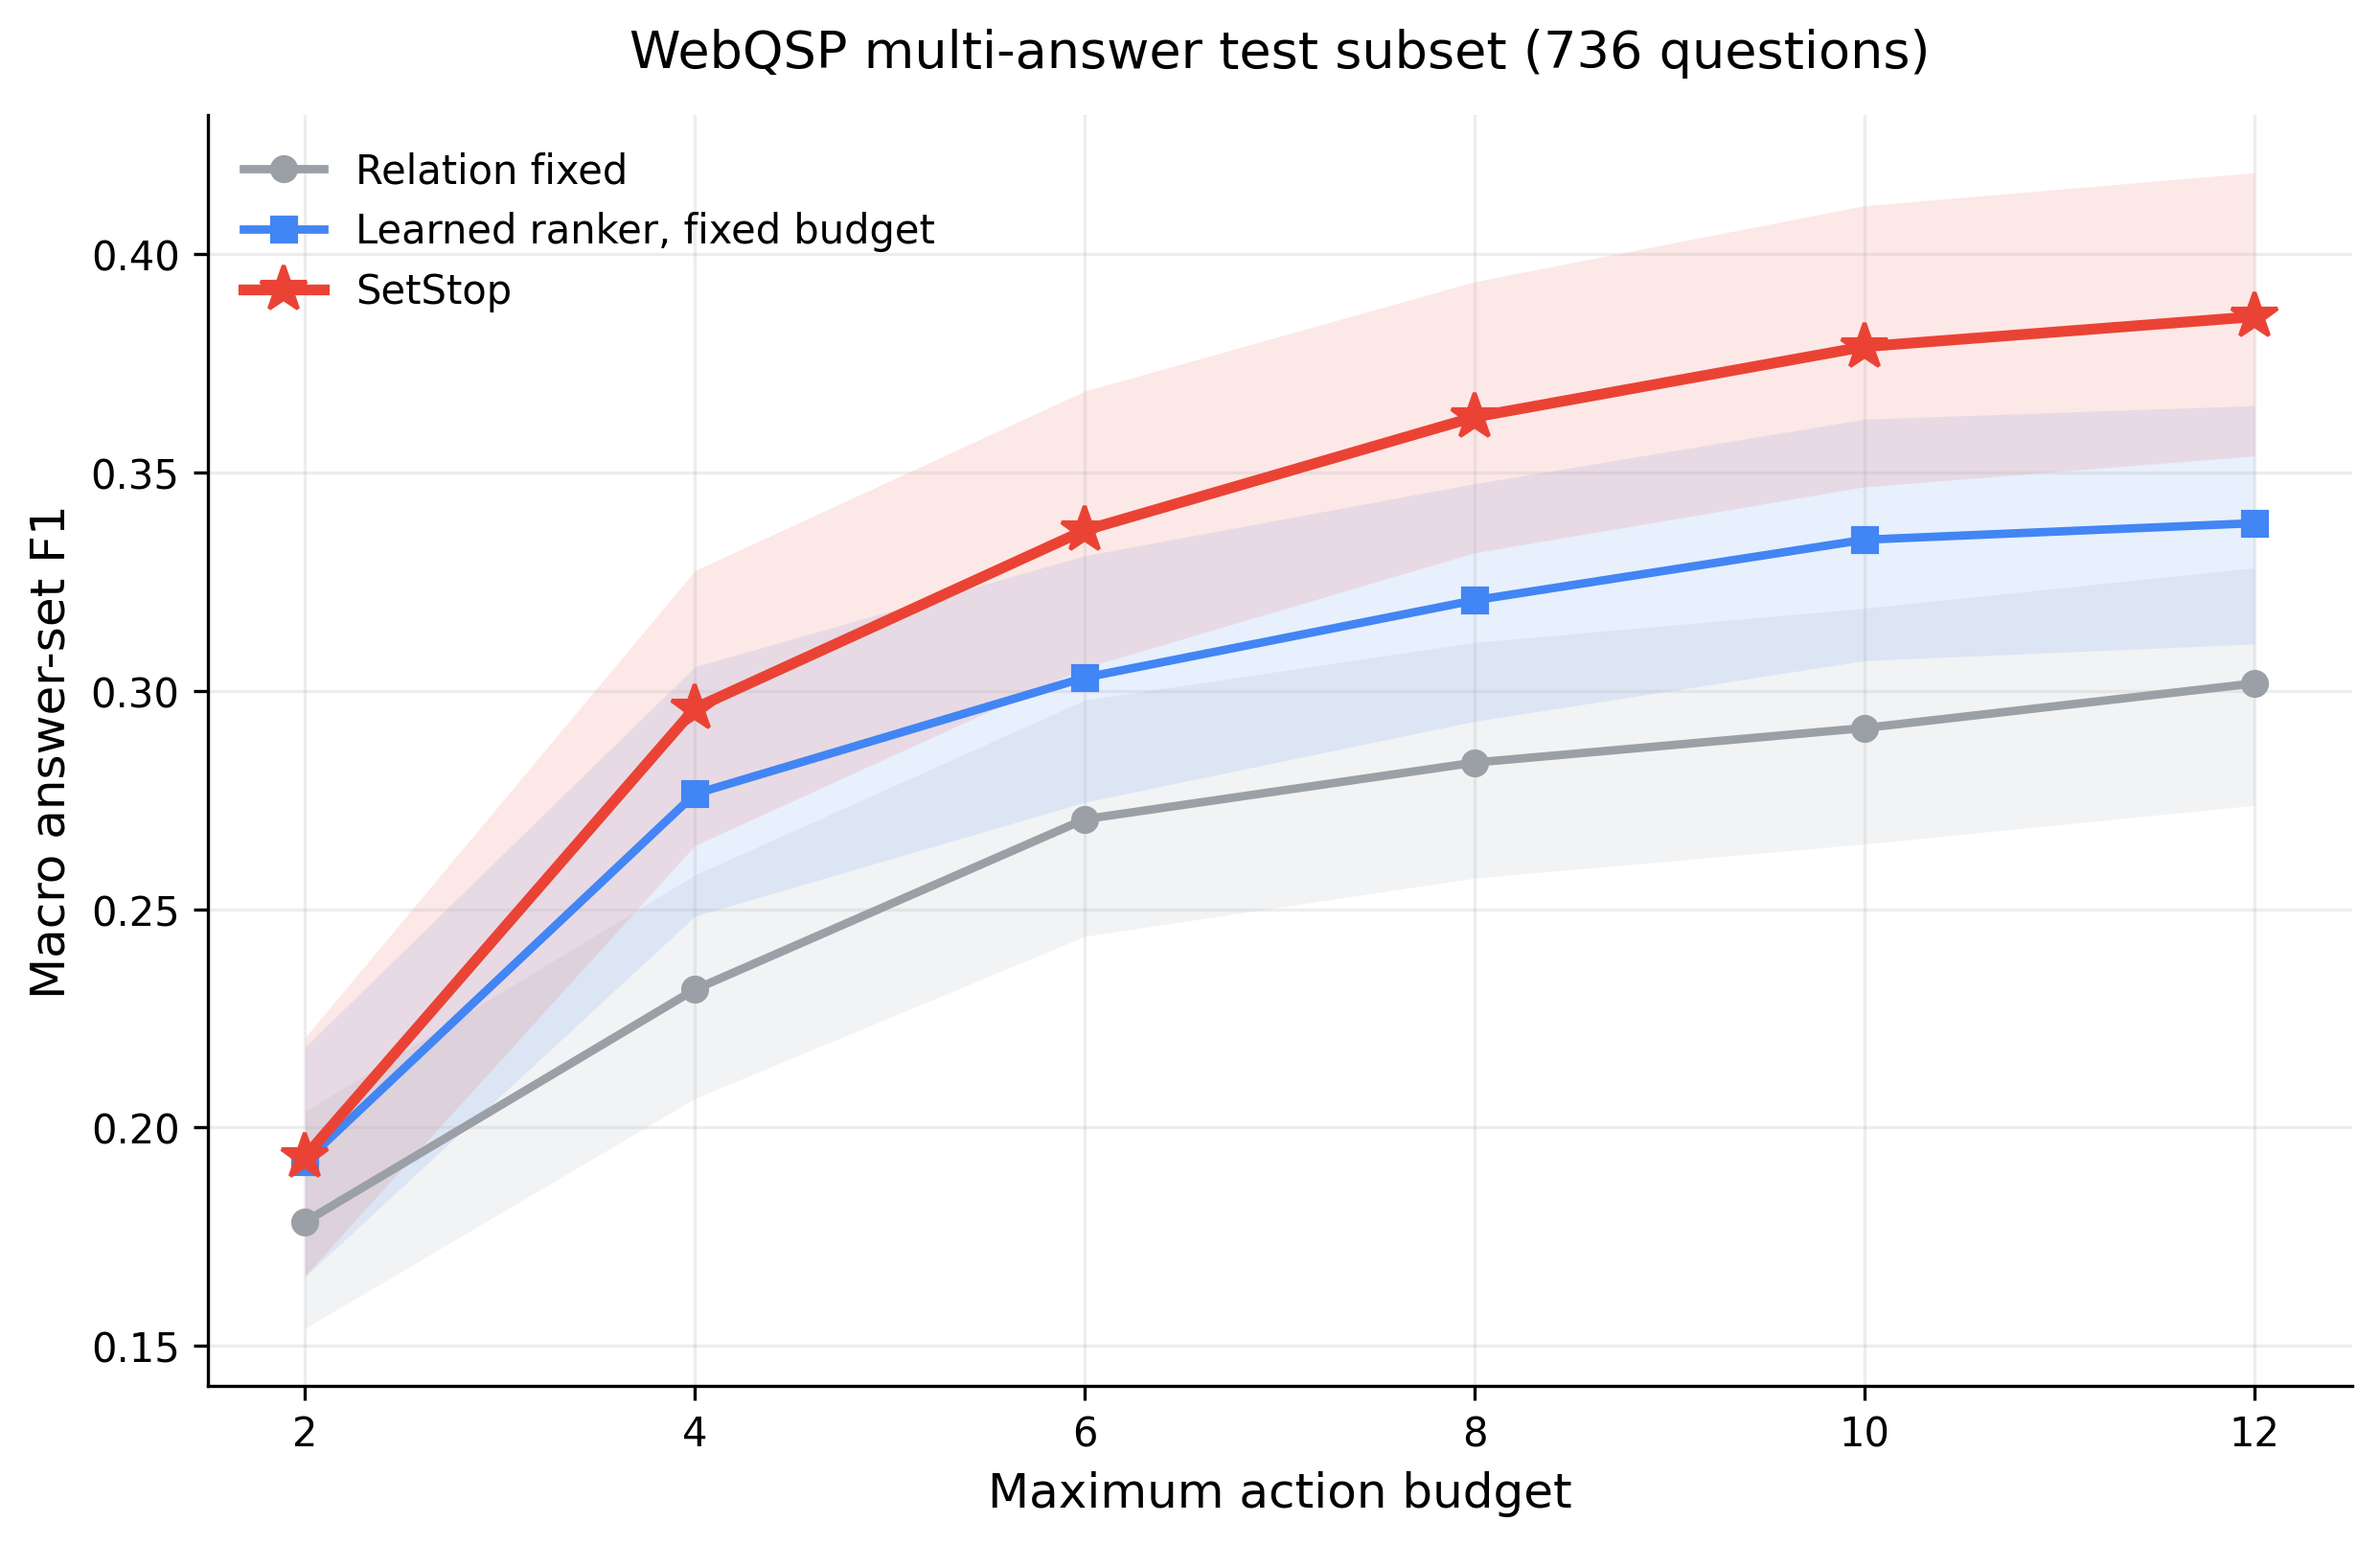

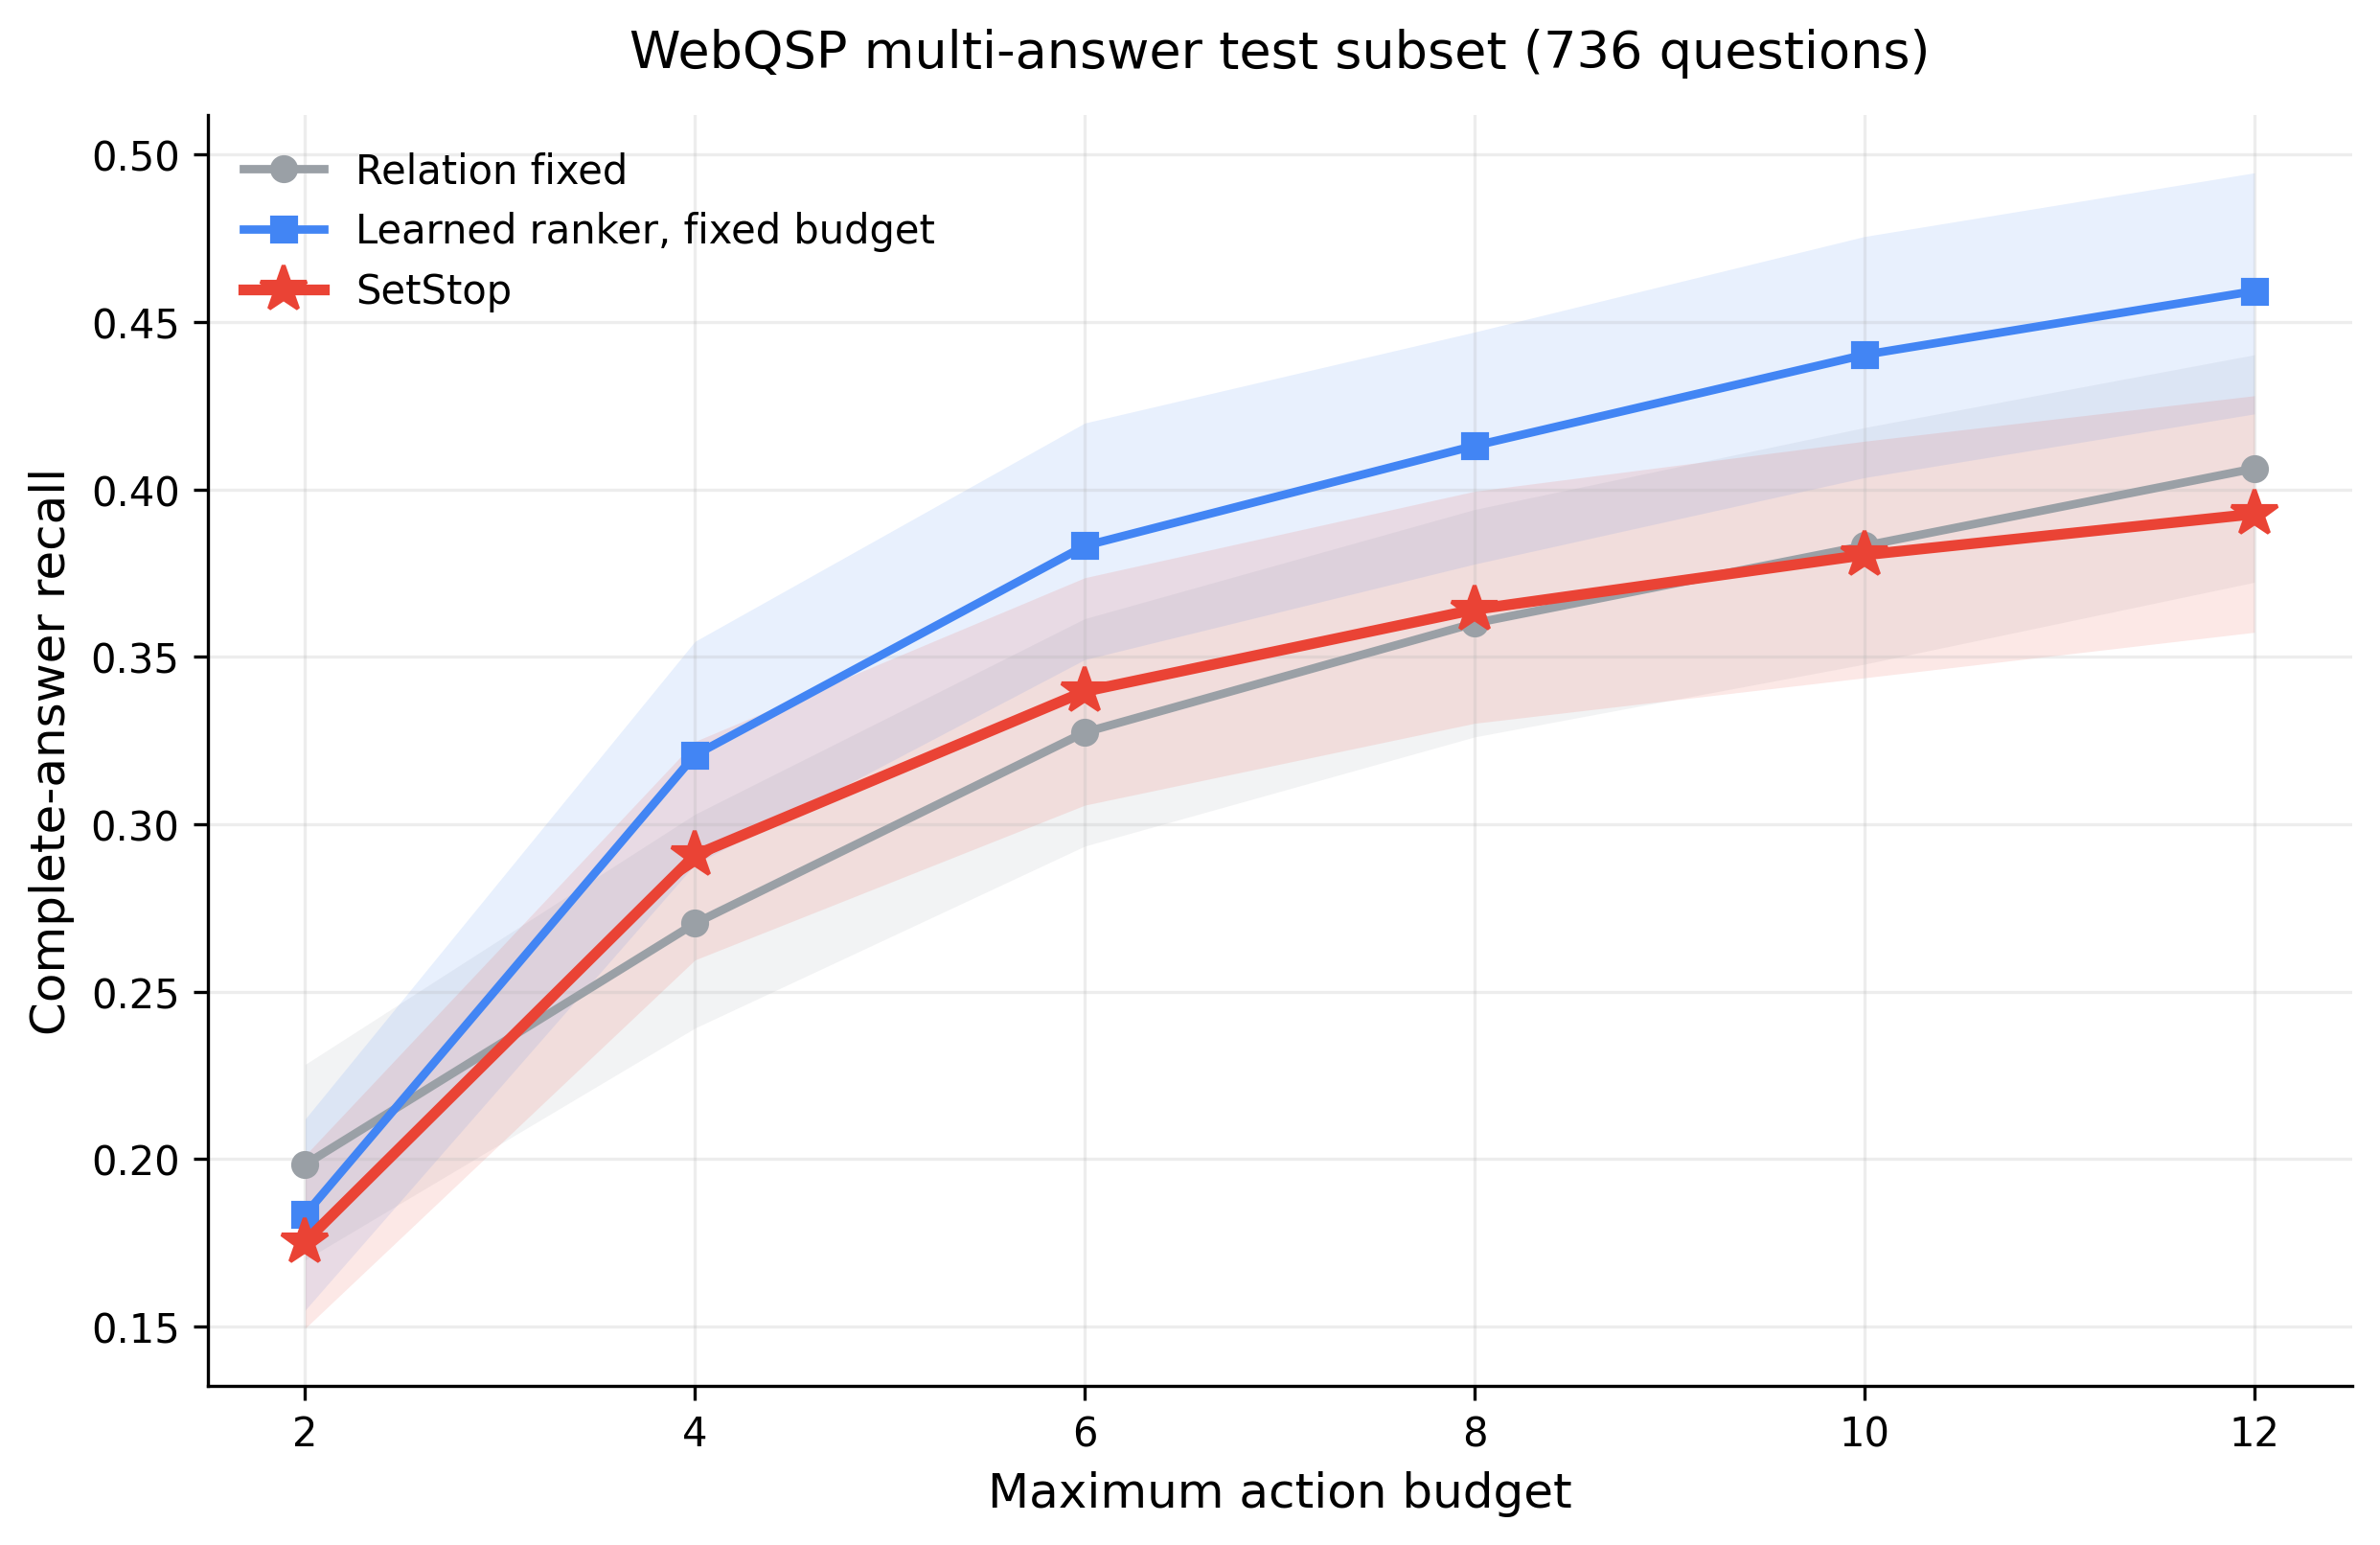

In [1]:
# =============================================================================
# SETSTOP-KGQA COST-MATCHED ABLATION
# OUTPUT-RECOVERY CELL
#
# Run this in a new cell after the Matplotlib PDF error.
# It does NOT rerun model inference.
# =============================================================================

import collections
import hashlib
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False,
)

# Force Matplotlib to use only its PNG-compatible Agg backend.
# We deliberately do not use Matplotlib's broken PDF backend.
import matplotlib

matplotlib.use(
    "Agg",
    force=True,
)

import matplotlib.pyplot as plt

try:
    plt.switch_backend("Agg")
except Exception:
    pass

from PIL import Image as PILImage
from IPython.display import (
    Image as DisplayImage,
    display,
)


# =============================================================================
# 1. PATHS
# =============================================================================

ROOT = Path(
    "/content/drive/MyDrive/SetStop_KGQA"
)

OUTPUT_ROOT = (
    ROOT
    / "outputs/cost_matched_ablation_v1"
)

SIGNATURE_PATH = (
    OUTPUT_ROOT
    / "evaluation_config_v1.json"
)

DEV_PER_QUESTION_PATH = (
    OUTPUT_ROOT
    / "dev_budget_per_question_v1.jsonl"
)

TEST_PER_QUESTION_PATH = (
    OUTPUT_ROOT
    / "test_budget_per_question_v1.jsonl"
)

DEV_RESULTS_PATH = (
    OUTPUT_ROOT
    / "dev_budget_results_v1.csv"
)

TEST_RESULTS_PATH = (
    OUTPUT_ROOT
    / "test_budget_results_v1.csv"
)

REGRESSION_PATH = (
    OUTPUT_ROOT
    / "notebook06_regression_check_v1.json"
)

PAIRED_BOOTSTRAP_PATH = (
    OUTPUT_ROOT
    / "paired_bootstrap_cost_matched_v1.json"
)

COST_MATCHED_PATH = (
    OUTPUT_ROOT
    / "cost_matched_comparisons_v1.json"
)

PAPER_TABLE_PATH = (
    OUTPUT_ROOT
    / "cost_matched_table_v1.csv"
)

F1_PNG_PATH = (
    OUTPUT_ROOT
    / "budget_f1_curve_v1.png"
)

F1_PDF_PATH = (
    OUTPUT_ROOT
    / "budget_f1_curve_v1.pdf"
)

COMPLETE_PNG_PATH = (
    OUTPUT_ROOT
    / "budget_complete_recall_curve_v1.png"
)

COMPLETE_PDF_PATH = (
    OUTPUT_ROOT
    / "budget_complete_recall_curve_v1.pdf"
)

SUMMARY_PATH = (
    OUTPUT_ROOT
    / "cost_matched_ablation_summary_v1.json"
)

INVENTORY_PATH = (
    OUTPUT_ROOT
    / "artifact_inventory_v1.json"
)

required_paths = [
    SIGNATURE_PATH,
    DEV_PER_QUESTION_PATH,
    TEST_PER_QUESTION_PATH,
    DEV_RESULTS_PATH,
    TEST_RESULTS_PATH,
    REGRESSION_PATH,
    PAIRED_BOOTSTRAP_PATH,
    COST_MATCHED_PATH,
    PAPER_TABLE_PATH,
]

for path in required_paths:
    assert path.exists(), (
        f"Required completed output is missing:\n{path}"
    )

print("=" * 108)
print(
    "SETSTOP-KGQA COST-MATCHED ABLATION "
    "OUTPUT RECOVERY"
)
print("=" * 108)
print("No model inference will be rerun.")
print("Output directory:", OUTPUT_ROOT)


# =============================================================================
# 2. LOAD COMPLETED RESULTS
# =============================================================================

evaluation_signature = json.loads(
    SIGNATURE_PATH.read_text(
        encoding="utf-8"
    )
)

regression_check = json.loads(
    REGRESSION_PATH.read_text(
        encoding="utf-8"
    )
)

paired_outputs = json.loads(
    PAIRED_BOOTSTRAP_PATH.read_text(
        encoding="utf-8"
    )
)

cost_matched_comparisons = json.loads(
    COST_MATCHED_PATH.read_text(
        encoding="utf-8"
    )
)

dev_df = pd.read_csv(
    DEV_RESULTS_PATH
)

test_df = pd.read_csv(
    TEST_RESULTS_PATH
)

assert len(dev_df) == 18, (
    f"Expected 18 dev configurations, "
    f"found {len(dev_df)}"
)

assert len(test_df) == 18, (
    f"Expected 18 test configurations, "
    f"found {len(test_df)}"
)

assert (
    regression_check["status"]
    == "PASS"
), (
    "Notebook-06 regression check did not pass. "
    "Do not use these results."
)

assert (
    regression_check[
        "maximum_absolute_difference"
    ]
    <= 1e-10
), (
    "Notebook-06 reproduction difference "
    "is larger than the allowed tolerance."
)

ACTION_CAPS = [
    int(value)
    for value in evaluation_signature[
        "action_caps"
    ]
]

POLICIES = [
    "relation_fixed",
    "learned_ranker_fixed",
    "setstop",
]

POLICY_LABELS = {
    "relation_fixed":
        "Relation fixed",
    "learned_ranker_fixed":
        "Learned ranker, fixed budget",
    "setstop":
        "SetStop",
}

COLORS = {
    "relation_fixed":
        "#9AA0A6",
    "learned_ranker_fixed":
        "#4285F4",
    "setstop":
        "#EA4335",
}

MARKERS = {
    "relation_fixed": "o",
    "learned_ranker_fixed": "s",
    "setstop": "*",
}

print(
    "Loaded completed configurations:",
    len(test_df),
)

print(
    "Notebook-06 regression check:",
    regression_check["status"],
)


# =============================================================================
# 3. SAFE PNG-TO-PDF CONVERSION
# =============================================================================

def png_to_pdf(
    png_path,
    pdf_path,
):
    """
    Convert a 300-DPI PNG to PDF using Pillow.
    This avoids Matplotlib's incompatible backend_pdf module.
    """

    with PILImage.open(
        png_path
    ) as source:
        if source.mode == "RGBA":
            background = PILImage.new(
                "RGB",
                source.size,
                "white",
            )

            background.paste(
                source,
                mask=source.getchannel(
                    "A"
                ),
            )

            image = background

        else:
            image = source.convert(
                "RGB"
            )

        image.save(
            pdf_path,
            format="PDF",
            resolution=300.0,
        )

    assert pdf_path.exists()
    assert pdf_path.stat().st_size > 0


# =============================================================================
# 4. GENERATE PAPER FIGURES
# =============================================================================

def plot_budget_curve(
    dataframe,
    metric,
    lower_key,
    upper_key,
    ylabel,
    png_path,
    pdf_path,
):
    figure, axis = plt.subplots(
        figsize=(8.4, 5.5)
    )

    for policy in POLICIES:
        policy_rows = (
            dataframe[
                dataframe["policy"]
                == policy
            ]
            .sort_values(
                "budget_cap"
            )
        )

        assert (
            len(policy_rows)
            == len(ACTION_CAPS)
        )

        x = policy_rows[
            "budget_cap"
        ].to_numpy(
            dtype=float
        )

        y = policy_rows[
            metric
        ].to_numpy(
            dtype=float
        )

        lower = policy_rows[
            lower_key
        ].to_numpy(
            dtype=float
        )

        upper = policy_rows[
            upper_key
        ].to_numpy(
            dtype=float
        )

        marker_size = (
            12
            if policy == "setstop"
            else 6
        )

        line_width = (
            2.7
            if policy == "setstop"
            else 2.1
        )

        axis.plot(
            x,
            y,
            marker=MARKERS[policy],
            markersize=marker_size,
            linewidth=line_width,
            color=COLORS[policy],
            label=POLICY_LABELS[
                policy
            ],
            zorder=3,
        )

        axis.fill_between(
            x,
            lower,
            upper,
            color=COLORS[policy],
            alpha=0.12,
            linewidth=0,
            zorder=1,
        )

    axis.set_xticks(
        ACTION_CAPS
    )

    axis.set_xlabel(
        "Maximum action budget",
        fontsize=12,
    )

    axis.set_ylabel(
        ylabel,
        fontsize=12,
    )

    axis.set_title(
        "WebQSP multi-answer test subset "
        "(736 questions)",
        fontsize=13,
        pad=12,
    )

    axis.grid(
        axis="both",
        alpha=0.22,
        linewidth=0.8,
    )

    axis.spines[
        "top"
    ].set_visible(False)

    axis.spines[
        "right"
    ].set_visible(False)

    axis.legend(
        frameon=False,
        fontsize=10,
        loc="best",
    )

    figure.tight_layout()

    # Only ask Matplotlib to create PNG.
    figure.savefig(
        png_path,
        format="png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(figure)

    assert png_path.exists()
    assert png_path.stat().st_size > 0

    # Pillow handles PDF creation instead of Matplotlib.
    png_to_pdf(
        png_path,
        pdf_path,
    )

    return png_path, pdf_path


f1_png, f1_pdf = (
    plot_budget_curve(
        dataframe=test_df,
        metric="macro_f1",
        lower_key=(
            "macro_f1_ci95_lower"
        ),
        upper_key=(
            "macro_f1_ci95_upper"
        ),
        ylabel=(
            "Macro answer-set F1"
        ),
        png_path=F1_PNG_PATH,
        pdf_path=F1_PDF_PATH,
    )
)

complete_png, complete_pdf = (
    plot_budget_curve(
        dataframe=test_df,
        metric="complete_recall",
        lower_key=(
            "complete_recall_"
            "ci95_lower"
        ),
        upper_key=(
            "complete_recall_"
            "ci95_upper"
        ),
        ylabel=(
            "Complete-answer recall"
        ),
        png_path=(
            COMPLETE_PNG_PATH
        ),
        pdf_path=(
            COMPLETE_PDF_PATH
        ),
    )
)

print(
    "Generated:",
    F1_PNG_PATH.name,
    F1_PDF_PATH.name,
)

print(
    "Generated:",
    COMPLETE_PNG_PATH.name,
    COMPLETE_PDF_PATH.name,
)


# =============================================================================
# 5. RECREATE FINAL SUMMARY
# =============================================================================

primary_test = (
    cost_matched_comparisons[
        "test"
    ][
        "setstop_vs_learned_cap6"
    ]
)

primary_relation_test = (
    cost_matched_comparisons[
        "test"
    ][
        "setstop_vs_relation_cap6"
    ]
)

primary_paired = (
    paired_outputs[
        "test"
    ][
        "primary_cost_matched_vs_learned"
    ]
)

primary_relation_paired = (
    paired_outputs[
        "test"
    ][
        "primary_cost_matched_vs_relation"
    ]
)

runtime_minutes = None

if "evaluation_start" in globals():
    try:
        runtime_minutes = float(
            (
                time.time()
                - evaluation_start
            )
            / 60
        )
    except Exception:
        runtime_minutes = None

gpu_name = "Tesla T4"

if "GPU_NAME" in globals():
    gpu_name = str(GPU_NAME)

summary_output = {
    "experiment": (
        "SetStop-KGQA cost-matched "
        "action-budget ablation"
    ),
    "status": "completed",
    "data": {
        "dev_questions": 118,
        "test_questions": 736,
        "configurations_per_split":
            18,
    },
    "runtime": {
        "gpu": gpu_name,
        "runtime_minutes_including_recovery":
            runtime_minutes,
        "recovery_note": (
            "Core inference completed before "
            "a Matplotlib PDF-backend import "
            "error. Figures were regenerated "
            "from saved results, and PNG files "
            "were converted to PDF using Pillow."
        ),
    },
    "frozen_configuration":
        evaluation_signature,
    "regression_check":
        regression_check,
    "primary_cost_matched_test_comparison":
        primary_test,
    "primary_cost_matched_relation_comparison":
        primary_relation_test,
    "primary_paired_bootstrap":
        primary_paired,
    "primary_relation_paired_bootstrap":
        primary_relation_paired,
    "reporting_protocol": {
        "setstop_configuration": (
            "Frozen threshold 0.71 with "
            "maximum action cap 12"
        ),
        "action_matched_comparator": (
            "Learned ranker with fixed "
            "action cap 6"
        ),
        "reason_for_cap_6": (
            "SetStop used 5.952 mean actions "
            "in the frozen Notebook-06 "
            "evaluation; six is its rounded "
            "fixed-action comparison."
        ),
        "test_selection": (
            "No threshold or accuracy-based "
            "operating point was selected "
            "using test results."
        ),
        "required_reporting": (
            "Report all predefined action "
            "caps [2, 4, 6, 8, 10, 12], "
            "not only the strongest point."
        ),
        "cost_caution": (
            "Action count and retrieved-edge "
            "count are both reported because "
            "one action can expose different "
            "numbers of graph edges."
        ),
    },
}

SUMMARY_PATH.write_text(
    json.dumps(
        summary_output,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

assert SUMMARY_PATH.exists()


# =============================================================================
# 6. ARTIFACT INVENTORY
# =============================================================================

def sha256_file(path):
    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as file:
        for block in iter(
            lambda:
                file.read(
                    1024 * 1024
                ),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


artifact_paths = [
    SIGNATURE_PATH,
    DEV_PER_QUESTION_PATH,
    TEST_PER_QUESTION_PATH,
    DEV_RESULTS_PATH,
    TEST_RESULTS_PATH,
    REGRESSION_PATH,
    PAIRED_BOOTSTRAP_PATH,
    COST_MATCHED_PATH,
    PAPER_TABLE_PATH,
    F1_PNG_PATH,
    F1_PDF_PATH,
    COMPLETE_PNG_PATH,
    COMPLETE_PDF_PATH,
    SUMMARY_PATH,
]

inventory = {
    "experiment": (
        "cost_matched_ablation_v1"
    ),
    "artifacts": [
        {
            "name":
                path.name,
            "path":
                str(path),
            "bytes":
                int(
                    path.stat().st_size
                ),
            "sha256":
                sha256_file(path),
        }
        for path in artifact_paths
    ],
}

INVENTORY_PATH.write_text(
    json.dumps(
        inventory,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


# =============================================================================
# 7. DISPLAY FINAL RESULTS
# =============================================================================

display_columns = [
    "method",
    "budget_cap",
    "macro_f1",
    "exact_match",
    "complete_recall",
    "mean_actions",
    "mean_retrieved_edges",
]

print("\n" + "=" * 118)
print("TEST ACTION-BUDGET RESULTS")
print("=" * 118)

print(
    test_df[
        display_columns
    ].to_string(
        index=False,
        float_format=
            lambda value:
                f"{value:.4f}",
    )
)

first = primary_test["first"]
second = primary_test["second"]

delta = primary_test[
    "delta_first_minus_second"
]

f1_bootstrap = (
    primary_paired[
        "metrics"
    ][
        "answer_f1"
    ]
)

complete_bootstrap = (
    primary_paired[
        "metrics"
    ][
        "complete_recall"
    ]
)

edge_bootstrap = (
    primary_paired[
        "metrics"
    ][
        "retrieved_edges"
    ]
)

print("\n" + "=" * 118)
print(
    "PRIMARY ACTION-MATCHED COMPARISON"
)
print("=" * 118)

print(
    "SetStop: frozen adaptive threshold, "
    "maximum cap 12"
)

print(
    "Comparator: learned ranker, "
    "fixed cap 6"
)

print("-" * 118)

print(
    f"{'Method':<34}"
    f"{'Macro F1':>12}"
    f"{'Exact':>12}"
    f"{'Complete':>12}"
    f"{'Actions':>12}"
    f"{'Edges':>14}"
)

print(
    f"{'SetStop':<34}"
    f"{first['macro_f1']:>12.4f}"
    f"{first['exact_match']:>12.4f}"
    f"{first['complete_recall']:>12.4f}"
    f"{first['mean_actions']:>12.4f}"
    f"{first['mean_retrieved_edges']:>14.2f}"
)

print(
    f"{'Learned ranker, fixed cap 6':<34}"
    f"{second['macro_f1']:>12.4f}"
    f"{second['exact_match']:>12.4f}"
    f"{second['complete_recall']:>12.4f}"
    f"{second['mean_actions']:>12.4f}"
    f"{second['mean_retrieved_edges']:>14.2f}"
)

print("-" * 118)

print(
    f"Macro-F1 difference: "
    f"{delta['macro_f1']:+.4f}"
)

print(
    "Paired 95% CI for F1 difference: "
    f"[{f1_bootstrap['ci95_lower']:+.4f}, "
    f"{f1_bootstrap['ci95_upper']:+.4f}]"
)

print(
    f"Complete-recall difference: "
    f"{delta['complete_recall']:+.4f}"
)

print(
    "Paired 95% CI for complete recall: "
    f"[{complete_bootstrap['ci95_lower']:+.4f}, "
    f"{complete_bootstrap['ci95_upper']:+.4f}]"
)

print(
    f"Retrieved-edge difference: "
    f"{delta['mean_retrieved_edges']:+.2f}"
)

print(
    "Paired 95% CI for edge difference: "
    f"[{edge_bootstrap['ci95_lower']:+.2f}, "
    f"{edge_bootstrap['ci95_upper']:+.2f}]"
)

print(
    "\nNotebook-06 reproduction:",
    regression_check["status"],
)

print("\nGenerated figures:")
print(F1_PNG_PATH)
print(F1_PDF_PATH)
print(COMPLETE_PNG_PATH)
print(COMPLETE_PDF_PATH)

print("\nFinal summary:")
print(SUMMARY_PATH)

print("\nArtifact inventory:")
print(INVENTORY_PATH)

print("\n" + "=" * 118)
print(
    "OUTPUT RECOVERY COMPLETED SUCCESSFULLY"
)
print("=" * 118)

display(
    DisplayImage(
        filename=str(
            F1_PNG_PATH
        )
    )
)

display(
    DisplayImage(
        filename=str(
            COMPLETE_PNG_PATH
        )
    )
)